# T21: load_smarts_fits fails clearly when no sector survives

Companion notebook to `README.md` in this folder. Running top-to-bottom regenerates every figure in `figures/` from the saved results in `data/` (or the referenced `runs/` directory).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-10-21_t21-loader-no-usable-sectors"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


## Example: an all-flagged request

`smarts-tess-v1.0-828115` has both orbits of sectors 1 and 11 flagged (plus 21 and the trailing orbit 27). Requesting `sectors=[1, 11]` leaves nothing; before T21 this crashed in `to_even_cadence` with `attempt to get argmax of an empty sequence`.

NoUsableSectorsError: data/smarts_sample/smarts-tess-v1.0-828115.fits: no usable data in requested sectors [1, 11]: flagged [1, 11], absent [] (file has 27 orbits = sectors 1-14, 5 orbits flagged)


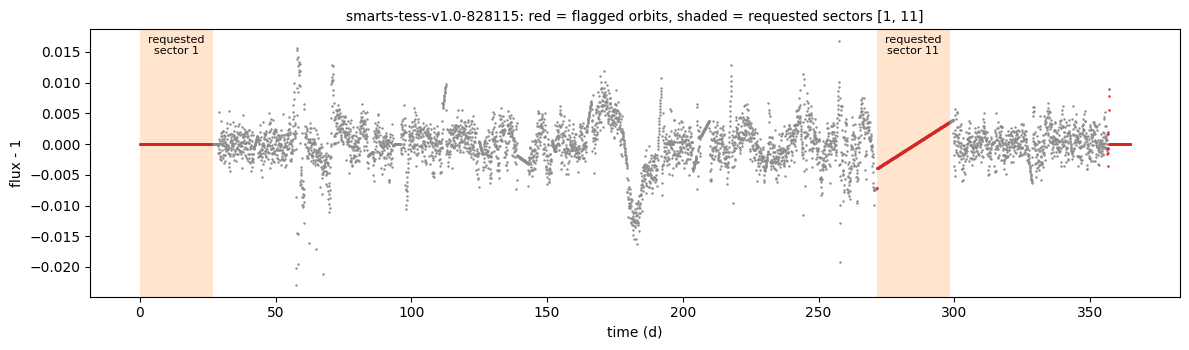

In [2]:
df = pd.read_csv(DATA / "example_828115.csv")
msg = (DATA / "example_828115_error.txt").read_text().strip()
print(msg)
requested = [1, 11]
fig, ax = plt.subplots(figsize=(12, 3.6))
for (orb, flg), g in df.groupby(["orbit", "flagged"]):
    ax.plot(g.time, g.flux, ".", ms=1.5, color="tab:red" if flg else "0.55")
for s in requested:
    g = df[df.sector == s]
    ax.axvspan(g.time.min(), g.time.max(), color="tab:orange", alpha=0.2, lw=0)
    ax.text(g.time.mean(), 0.98, f"requested\nsector {s}", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=8)
ax.set_xlabel("time (d)"); ax.set_ylabel("flux - 1")
ax.set_title("smarts-tess-v1.0-828115: red = flagged orbits, shaded = requested sectors [1, 11]", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "fig_example_828115.png", dpi=130)

## dev_small regression check

`tools/compare_runs.py` against the committed baselines (exit code 0 = bit-identical periods and outcomes).

In [3]:
import subprocess
for name in ["assigned", "fullyear"]:
    base = REPO / f"benchmarks/baselines/dev_small_{name}_tables"
    new = REPO / f"runs/t21_dev_small_{name}"
    r = subprocess.run([sys.executable, str(REPO / "tools/compare_runs.py"), str(base), str(new)],
                       capture_output=True, text=True)
    print(f"--- dev_small {name}: exit {r.returncode}"); print(r.stdout.strip())

--- dev_small assigned: exit 1
50 stars in common
final_period differs: 0 stars
final_outcome differs: 0 stars
  acf_fft                top1 differs:   0   n_candidates differs:   0
  acf_fft_highpass       top1 differs:   0   n_candidates differs:   0
  acf_fft_short          top1 differs:   0   n_candidates differs:   0
  lombscargle            top1 differs:   0   n_candidates differs:   0
  lombscargle_short      top1 differs:   0   n_candidates differs:   0
  pairwise_histogram     top1 differs:   0   n_candidates differs:   0
  wavelet                top1 differs:   1   n_candidates differs:   1
DIFFERENT


--- dev_small fullyear: exit 1
50 stars in common
final_period differs: 0 stars
final_outcome differs: 0 stars
  acf_fft                top1 differs:   0   n_candidates differs:   0
  acf_fft_highpass       top1 differs:   0   n_candidates differs:   0
  acf_fft_short          top1 differs:   0   n_candidates differs:   0
  lombscargle            top1 differs:   0   n_candidates differs:   0
  lombscargle_short      top1 differs:   0   n_candidates differs:   0
  pairwise_histogram     top1 differs:   0   n_candidates differs:   0
  wavelet                top1 differs:   1   n_candidates differs:   2
DIFFERENT


Final periods and outcomes are identical (0 stars differ) in both runs. The only differences are `wavelet`'s candidate counts on 1-2 stars. Those counts also change between two runs of *unmodified* HEAD (see README), and `wavelet` is not one of the pooled pipeline methods, so this is existing nondeterminism rather than a T21 effect.